# 6.3 - Linear models: the baseline every later model must beat

Notebook 6.2 built 45 features for every S&P 1500 member at every month end and tested each alone. Only two
predicted next month's return beyond what chance explains - share issuance and return on capital employed (ROCE) -
and both are factors this repository already has. Nine more came close.

This notebook asks whether a model that **combines** all 45 features does better than simply averaging the two
survivors. It uses the simplest models that can: four **penalised linear models**. If they cannot beat the plain
average out of sample, the more flexible models of the next phases (gradient boosting, neural networks) have to
explain why they would.

Everything is out of sample and walk-forward (notebook 6.1's protocol): each model is tuned and fitted on ten years
and judged on the following one, for every year from 2015 to 2024, and every setting tried is registered.

## The four models

All four predict a company's next-month return over the average member, $y$, as a weighted sum of its features
$x_1, \dots, x_p$: $\hat y = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$. Ordinary least squares would choose the
weights $\beta$ to make the squared errors as small as possible. With 45 features and a weak signal, that overfits:
it gives large weights to features that happened to line up with returns in the training years. A **penalty** on the
size of the weights pulls them towards zero, trading a little bias for much less variance (the bias-variance
trade-off of notebook 5.1):

| Model | Chooses $\beta$ to minimise | Effect of the penalty |
|---|---|---|
| **Ridge** (Hoerl and Kennard, 1970) | $\sum_i (y_i - \hat y_i)^2 + \alpha \sum_j \beta_j^2$ | every weight shrunk towards 0, none exactly 0; correlated features share the weight |
| **Lasso** (Tibshirani, 1996) | $\frac{1}{2n}\sum_i (y_i - \hat y_i)^2 + \alpha \sum_j \lvert\beta_j\rvert$ | weak features set exactly to 0: the model picks a few |
| **Elastic net** (Zou and Hastie, 2005) | the lasso's error plus $\alpha\left(\tfrac12\sum_j\lvert\beta_j\rvert + \tfrac14\sum_j\beta_j^2\right)$ | between the two: picks features, but shares weight among correlated ones |
| **Logistic regression** | the log-likelihood of "beats the average member or not", with an L2 penalty $\propto 1/C$ | predicts a probability, $1/(1 + e^{-\hat y})$; ignores *how much* a company beat the average |

The penalty's strength ($\alpha$, or $1/C$) is the one setting each model has. Too weak, and the model fits noise;
too strong, and every weight is zero. It is chosen by **nested cross-validation**: inside each ten-year training
window, the years are cut into five consecutive blocks; each candidate strength is fitted on four blocks and scored
(by rank IC) on the fifth, in turn, with the months whose labels touch the held-out block purged and one month after
it embargoed. The best strength is then refitted on the whole window. The test year plays no part in the choice.

## The protocol, fixed before any result

| Choice | Setting |
|---|---|
| Inputs | the 45 company features of 6.2, each as its percentile among the date's members less one half (from -0.5 to +0.5); a missing value is set to 0, the median |
| Target | next month's total return over the average member's, each date's extreme 1 % clipped (`labels.trimmed_excess`); the logistic model learns whether it is above 0 |
| Folds | test each year 2015-2024; train on the ten years before it; the last month before the test year purged |
| Tuning | purged 5-fold cross-validation inside each training window, embargo 1 month, by mean rank IC; a month in which a model ranks nobody (every weight penalised to 0) scores an IC of 0 |
| Grids | ridge $\alpha$ = 1 to $10^6$; lasso and elastic net $\alpha$ = $10^{-7}$ to $10^{-3}$; logistic $C$ = $10^{-4}$ to 1 (powers of ten) |
| Yardstick | the equal-weighted average of the percentiles of the two survivors of 6.2: minus share-count change (issuance) and ROCE |
| Judged by | out-of-sample rank IC against next month's return 2015-2024 and its Newey-West t; the difference from the yardstick's IC and its t |
| Registered | every grid point (its mean validation IC) and every model's out-of-sample result, in the new family `ml4t_linear_monthly` |

In [1]:
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research import evaluation as ev
from equity_research.research import labels as lb
from equity_research.research import linear as ln
from equity_research.research import store
from equity_research.research import validation as va
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data
from equity_research.research.features import unstack
from equity_research.research.registry import record_search, trial_count

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
charts.style()

UNIVERSE, START, END = "SP1500", "2005-01-01", "2024-12-31"  # END: the last day before the hold-out
FIRST_TEST, LAST_TEST, TRAIN_YEARS = 2015, 2024, 10
cache = ResearchCache()
SNAPSHOT = store.data_snapshot(cache)
data = load_universe_data(cache, UNIVERSE, START, END)
dates = data.rebalances
FEATURES = {"universe": UNIVERSE, "start": START, "end": END, "dates": "month ends", "version": 1}
long = store.load("features", "company_month_end", FEATURES, snapshot=SNAPSHOT)
assert long is not None, "run notebook 6.2 first: it builds the features for this data snapshot"
monthly = store.cached(
    "labels",
    "fwd_ret_month",
    {"universe": UNIVERSE, "start": START, "end": END, "dates": "rebalances"},
    lambda: lb.period_returns(data.returns, dates),
    snapshot=SNAPSHOT,
)
x = ln.centred_ranks(long)
y = lb.trimmed_excess(monthly, data.members)
ends = va.next_date_ends(dates)
folds = va.walk_forward(dates, ends, train_years=TRAIN_YEARS, first_test=FIRST_TEST, last_test=LAST_TEST)
print(f"{x.shape[1]} features, {len(x):,} member-months; {len(folds)} folds")
display(va.describe(folds).style.format({c: "{:%Y-%m}" for c in ("train from", "train to", "test from", "test to")}))

left out 887 facts of 2 companies in ['GBP']


45 features, 360,361 member-months; 10 folds


,train from,train to,train dates,purged,test from,test to,test dates
fold,,,,,,,
1,2005-01,2014-11,119,1,2015-01,2015-12,12
2,2006-01,2015-11,119,1,2016-01,2016-12,12
3,2007-01,2016-11,119,1,2017-01,2017-12,12
4,2008-01,2017-11,119,1,2018-01,2018-12,12
5,2009-01,2018-11,119,1,2019-01,2019-12,12
6,2010-01,2019-11,119,1,2020-01,2020-12,12
7,2011-01,2020-11,119,1,2021-01,2021-12,12
8,2012-01,2021-11,119,1,2022-01,2022-12,12
9,2013-01,2022-11,119,1,2023-01,2023-12,12


## Step 1 - fitting: tuned inside each fold, judged on the next year

Each model's walk-forward run (ten folds, five inner blocks, every grid point) is kept in the artifact store, so a
rerun on the same data reads it back.

In [2]:
STUDY = FEATURES | {
    "target": "trimmed excess, 1 %",
    "train_years": TRAIN_YEARS,
    "first_test": FIRST_TEST,
    "flat": "ic 0",
}
runs = {
    name: ln.stored_walk_forward(x, y, folds, ends, model, name=name, config=STUDY, snapshot=SNAPSHOT)
    for name, model in ln.MODELS.items()
}
panels = unstack(long)
yardstick = ln.composite({"issuance": -panels["share_change"], "ROCE": panels["ROCE"]}, data.members)
test_dates = dates[(dates.year >= FIRST_TEST) & (dates.year <= LAST_TEST)]
scores = {ln.MODELS[n].label: r.scores for n, r in runs.items()} | {
    "Composite (issuance + ROCE)": yardstick.loc[test_dates]
}
print("Chosen penalty in each fold")
display(pd.DataFrame({ln.MODELS[n].label: r.chosen for n, r in runs.items()}).T.style.format("{:.0e}"))

Chosen penalty in each fold


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Ridge,1e+00,1e+00,1e+00,1e+03,1e+02,1e+03,1e+03,1e+03,1e+03,1e+02
Lasso,1e-03,1e-04,1e-03,1e-04,1e-03,1e-05,1e-04,1e-05,1e-04,1e-07
Elastic net,1e-07,1e-04,1e-03,1e-03,1e-05,1e-07,1e-04,1e-05,1e-04,1e-07
Logistic regression,1e+00,1e-03,1e-01,1e-02,1e-02,1e-03,1e-03,1e-02,1e-03,1e-03


## Step 2 - out of sample, 2015-2024: do they beat the plain average?

For each model and the yardstick: the mean monthly rank IC against next month's return, its t-statistic, the share
of months it was positive, the top-minus-bottom fifth's return a month, the share of the top fifth replaced each month
and the month-to-month rank autocorrelation. Then each model's IC less the yardstick's, month by month, and the
t-statistic of that difference: whether the fitting added anything.

In [3]:
ics = pd.DataFrame({name: ev.ic_series(s, monthly, data.members) for name, s in scores.items()}).loc[test_dates]
table = ev.ic_summary(ics, lags=0)[["mean", "t_nw", "positive"]]
table["spread"] = [ev.quantile_spread(ev.quantile_returns(s, monthly, data.members)).mean() for s in scores.values()]
table["turnover"] = [ev.top_turnover(s.loc[test_dates], data.members).mean() for s in scores.values()]
table["rank autocorrelation"] = [
    ev.rank_autocorrelation(s.loc[test_dates], data.members).mean() for s in scores.values()
]
base = ics["Composite (issuance + ROCE)"]
versus = pd.DataFrame({name: ln.ic_difference(ics[name], base) for name in ics.columns[:-1]}).T
display(
    table.style.format(
        {
            "mean": "{:+.4f}",
            "t_nw": "{:+.2f}",
            "positive": "{:.0%}",
            "spread": "{:+.2%}",
            "turnover": "{:.0%}",
            "rank autocorrelation": "{:.2f}",
        }
    )
)
print("Each model's monthly IC less the composite's")
display(versus.style.format({"mean difference": "{:+.4f}", "t_nw": "{:+.2f}", "dates": "{:.0f}"}))

,mean,t_nw,positive,spread,turnover,rank autocorrelation
Ridge,+0.0139,+1.66,62%,+0.33%,37%,0.75
Lasso,+0.0053,+0.58,55%,+0.09%,32%,0.80
Elastic net,+0.0087,+0.91,58%,+0.23%,33%,0.79
Logistic regression,+0.0236,+2.67,65%,+0.34%,35%,0.76
Composite (issuance + ROCE),+0.0249,+3.18,66%,+0.35%,8%,0.97


Each model's monthly IC less the composite's


,mean difference,t_nw,dates
Ridge,-0.0111,-1.13,119
Lasso,-0.0196,-1.72,119
Elastic net,-0.0162,-1.38,119
Logistic regression,-0.0013,-0.18,119


Mean rank IC by year


,Ridge,Lasso,Elastic net,Logistic regression,Composite (issuance + ROCE)
2015,+0.017,+0.002,+0.017,+0.038,+0.025
2016,+0.047,+0.056,+0.052,-0.001,-0.025
2017,+0.008,-0.039,-0.039,+0.030,+0.058
2018,+0.017,+0.026,+0.010,+0.022,-0.008
2019,-0.003,-0.036,-0.004,+0.028,+0.034
2020,-0.014,-0.015,-0.013,-0.023,-0.006
2021,+0.034,+0.041,+0.040,+0.052,+0.050
2022,+0.028,+0.027,+0.027,+0.024,+0.027
2023,+0.020,+0.007,+0.013,+0.060,+0.086
2024,-0.017,-0.017,-0.017,+0.005,+0.009


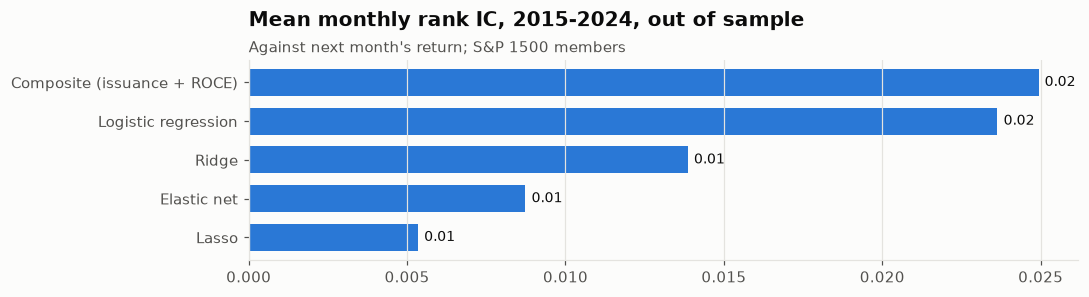

In [4]:
yearly = ics.groupby(ics.index.year).mean()
print("Mean rank IC by year")
display(yearly.style.format("{:+.3f}").background_gradient(cmap="RdYlGn", vmin=-0.08, vmax=0.08, axis=None))
fig = charts.ranked_bars(
    table["mean"],
    "Mean monthly rank IC, 2015-2024, out of sample",
    subtitle="Against next month's return; S&P 1500 members",
)

## Step 3 - the penalties chosen, and what the tuning saw

The mean validation IC of each penalty strength, averaged over the ten folds' tuning: a curve that is flat says the
choice barely mattered; a peak far from both ends says the penalty did real work.

In [5]:
for name, run in runs.items():
    curve = run.tuning.mean()
    print(f"{ln.MODELS[name].label}: mean validation IC by {ln.MODELS[name].parameter}")
    display(curve.to_frame("mean validation IC").T.style.format("{:+.4f}"))

Ridge: mean validation IC by alpha


,1.000000,10.000000,100.000000,1000.000000,10000.000000,100000.000000,1000000.000000
mean validation IC,+0.0150,+0.0151,+0.0152,+0.0149,+0.0089,-0.0016,-0.0052


Lasso: mean validation IC by alpha


,0.000000,0.000001,0.000010,0.000100,0.001000
mean validation IC,+0.0150,+0.0150,+0.0151,+0.0142,+0.0069


Elastic net: mean validation IC by alpha


,0.000000,0.000001,0.000010,0.000100,0.001000
mean validation IC,+0.0150,+0.0150,+0.0151,+0.0149,+0.0052


Logistic regression: mean validation IC by C


,0.000100,0.001000,0.010000,0.100000,1.000000
mean validation IC,+0.0145,+0.0201,+0.0212,+0.0210,+0.0209


## Step 4 - which features the models lean on, and whether they keep to it

Each fold's coefficients side by side (features are on one scale, so coefficients are comparable): the mean, the
spread, the share of folds that agree with the mean's sign, and - for the lasso - the share of folds that dropped the
feature altogether. A feature whose sign flips from fold to fold is not a reliable part of the model.

In [6]:
for name in ("ridge", "lasso"):
    stable = ln.coefficient_stability(runs[name].coefficients)
    print(f"{ln.MODELS[name].label}: the 12 largest coefficients (in units of next month's excess return)")
    display(
        stable.head(12).style.format(
            {"mean": "{:+.5f}", "sd": "{:.5f}", "same sign": "{:.0%}", "zero": "{:.0%}", "folds": "{:.0f}"}
        )
    )

Ridge: the 12 largest coefficients (in units of next month's excess return)


,mean,sd,same sign,zero,folds
ffd_price,-0.01455,0.00331,100%,0%,10
dollar_volume_1m,-0.00767,0.00756,100%,0%,10
garch_vol,-0.00749,0.00208,100%,0%,10
trend_slope,+0.00694,0.00253,100%,0%,10
amihud_1m,-0.00604,0.00612,100%,0%,10
mom_6_1,-0.00506,0.00232,100%,0%,10
vol_1m,+0.00486,0.00708,70%,0%,10
Asset Turnover,+0.00475,0.00120,100%,0%,10
Gross Profit Margin,+0.00404,0.00143,100%,0%,10
size,+0.00398,0.00338,100%,0%,10


Lasso: the 12 largest coefficients (in units of next month's excess return)


,mean,sd,same sign,zero,folds
ffd_price,-0.00923,0.00554,100%,0%,10
garch_vol,-0.00511,0.00414,70%,30%,10
trend_slope,+0.00379,0.00507,50%,50%,10
Asset Turnover,+0.00300,0.00268,70%,30%,10
mom_6_1,-0.00198,0.00303,50%,50%,10
amihud_1m,-0.00196,0.00599,30%,70%,10
dollar_volume_1m,-0.00189,0.00598,10%,90%,10
sales_growth,+0.00181,0.00155,70%,30%,10
ret_1m,-0.00164,0.00194,50%,50%,10
zero_days_3m,-0.00156,0.00150,70%,30%,10


## Step 5 - how uncertain a single prediction is: conformal intervals

A ranking can be useful even when each prediction is very uncertain, but it helps to see how uncertain. **Split
conformal prediction** gives an interval with a guaranteed coverage under one assumption (that the calibration errors
and the future errors are exchangeable): fit the model on the training years but the last, take the absolute errors
on that last year, and use their 90th percentile $q$ (a slightly higher rank, $\lceil (n+1)\,0.9 \rceil$, for the
guarantee) as the half-width of every interval $\hat y \pm q$. The test year then shows whether 90 % of outcomes
really fell inside - and how $q$ compares with how much the predictions themselves vary.

In [7]:
bands = ln.conformal(x, y, folds, ends, ln.MODELS["ridge"], penalties=runs["ridge"].chosen.to_dict())
display(
    bands.style.format(
        {"half-width": "{:.2%}", "coverage": "{:.1%}", "prediction sd": "{:.3%}", "outcome sd": "{:.2%}"}
    )
)
ratio = bands["half-width"].mean() / bands["prediction sd"].mean()
print(f"Average coverage {bands['coverage'].mean():.1%}; the half-width is {ratio:.0f} times the predictions' spread")

,half-width,coverage,prediction sd,outcome sd
test year,,,,
2015,11.27%,85.8%,0.568%,8.20%
2016,13.07%,88.9%,0.560%,8.59%
2017,14.10%,92.5%,0.542%,7.65%
2018,12.32%,87.4%,0.520%,8.39%
2019,13.49%,88.2%,0.570%,8.87%
2020,14.41%,81.6%,0.353%,12.64%
2021,19.74%,96.1%,0.390%,8.55%
2022,13.90%,87.6%,0.386%,9.36%
2023,15.31%,91.4%,0.415%,8.78%


Average coverage 89.0%; the half-width is 30 times the predictions' spread


## Step 6 - registering the search

Every grid point of every model (with its mean validation IC over the folds) and every model's out-of-sample result
are registered in `ml4t_linear_monthly`, so any later model judged against these counts the whole search.

In [8]:
# the registry is the shared database: connected only now, as a serverless database pauses when idle
engine = get_engine()
common = {
    "inputs": "6.2 company features, centred percentiles",
    "target": "trimmed excess next month",
    "folds": f"walk-forward {FIRST_TEST}-{LAST_TEST}, {TRAIN_YEARS} years, purged",
}
for name, run in runs.items():
    points = [
        (common | {"model": name, ln.MODELS[name].parameter: float(v)}, {"validation_ic": float(ic)})
        for v, ic in run.tuning.mean().items()
    ]
    record_search(engine, ln.FAMILY, points, search=f"{name} grid")
oos = [
    (
        common | {"model": name, "tuning": "nested purged 5-fold, embargo 1"},
        {"oos_ic": float(table.loc[label, "mean"]), "oos_t": float(table.loc[label, "t_nw"])},
    )
    for name, label in ((n, ln.MODELS[n].label) for n in ln.MODELS)
]
oos.append(
    (
        common | {"model": "composite", "parts": ["-share_change", "ROCE"]},
        {"oos_ic": float(table.iloc[-1]["mean"]), "oos_t": float(table.iloc[-1]["t_nw"])},
    )
)
record_search(engine, ln.FAMILY, oos, search="out of sample")
print("Trials registered in the family:", trial_count(engine, ln.FAMILY))

Trials registered in the family: 27


## Findings

**In short: no linear model beats the plain average of issuance and ROCE out of sample.** Logistic regression comes
closest and ties it, at four times the trading.

**1. The out-of-sample ranking, 2015-2024 (step 2).** Mean monthly rank IC against next month's return:

| Score | mean IC | t | difference from the composite (t) |
|---|---|---|---|
| Composite (issuance + ROCE) | +0.0249 | +3.18 | - |
| Logistic regression | +0.0236 | +2.67 | -0.0013 (-0.18) |
| Ridge | +0.0139 | +1.66 | -0.0111 (-1.13) |
| Elastic net | +0.0087 | +0.91 | -0.0162 (-1.38) |
| Lasso | +0.0053 | +0.58 | -0.0196 (-1.72) |

Only logistic regression has a t-statistic above 2, and its gap to the composite (-0.0013, t -0.18) is no gap at all.
The ridge, lasso and elastic-net models predict the size of the excess return and do worse. The logistic model
predicts only *whether* a company beats the average, so an extreme month moves it no more than an ordinary one -
the lesson of notebooks 5.2-5.3 again.

**2. A caution that favours the composite.** Its two parts were chosen by 6.2's triage over 2005-2024, which includes
these test years, so its +0.0249 is flattered by hindsight. The models' numbers are fully out of sample. Even so,
the models do not get ahead of it, and the honest conclusion is that combining 45 features linearly adds nothing
measurable to the two that survived on their own.

**3. The models cost far more to trade (step 2).** Each month they replace 32-37 % of their top fifth, against 8 % for
the composite, and their rankings correlate only 0.75-0.80 with the month before, against 0.97. Their top-minus-bottom
fifth earned +0.09 % to +0.34 % a month, the composite +0.35 %. So the composite is better per unit of trading, and
not worse in IC.

**4. The penalty barely mattered until it killed the signal (step 3).**

* **Ridge** - the mean validation IC is +0.0150 to +0.0152 for every alpha from 1 to 1,000 and falls only beyond
  (+0.0089 at 10,000, -0.0052 at a million). The folds chose between 1 and 1,000.
* **Logistic** - it is flat at about +0.021 for C from 0.01 to 1.
* **Lasso and elastic net** - they do best barely penalised (+0.0151).

A first execution of this notebook averaged the tuning only over the months a model ranked someone, so it scored
the lasso's strongest penalty, which ranks nobody in some months, at +0.0174. With such months counted as an IC of
0, the protocol's rule from 5.3, it scores +0.0069. No fold's choice changed and the out-of-sample results are
identical, but the averaged curve was misleading. The rule is now in `evaluation.ic_flat_zero` and used by every
tuning loop.

**5. What the models lean on, and whether they keep to it (step 4).** All but one of the ridge model's twelve largest
coefficients keep their sign in every fold:

* **The largest:** the fractionally differenced price (-0.015), dollar volume (-0.008), the GARCH volatility forecast
  (-0.007), the Kalman trend (+0.007), Amihud illiquidity (-0.006), six-month momentum (-0.005), asset turnover,
  gross margin, size and sales growth (all positive).
* **The exception:** one-month volatility (70 % of folds).

Two cautions. The largest coefficient, the fractionally differenced price, was not a discovery on its own (t -1.86
in 6.2). And correlated features share and trade weight: dollar volume and Amihud illiquidity both enter negatively
though they measure liquidity in opposite directions, and size enters positively beside them. No single coefficient
can be read as that feature's effect. The lasso keeps only the fractionally differenced price in every fold; its
other features drop in and out (in 30-70 % of folds), the mark of weak and interchangeable signals.

**6. A single prediction says almost nothing (step 5).** The split-conformal 90 % intervals covered 89.0 % of
outcomes on average (81.6 % in 2020, 96.1 % in 2021), so they are honest. But their half-width is 11-20 % of a
month's return, about 30 times the spread of the predictions themselves (0.35-0.57 %). The models rank companies
slightly better than chance across hundreds of them. About any one company's next month they know almost nothing.
That is normal for return prediction, and why breadth (6.1) is the whole game.

**What this means for P3.** Gradient boosting must beat a logistic regression at IC +0.024 and a composite at
+0.025 - the second flattered by hindsight - at a turnover a portfolio can afford. The 27 configurations tried here
(22 grid points, 4 tuned models and the composite) are registered in `ml4t_linear_monthly`.


## Glossary

* **Penalised (regularised) regression** - least squares with a cost on the size of the coefficients, to stop the fit
  from chasing noise.
* **Ridge / lasso / elastic net** - an L2 penalty (squares of the weights), an L1 penalty (absolute values, which can
  set weights exactly to zero), or a mix.
* **Logistic regression** - a linear model of the log-odds of a yes/no outcome; its prediction is a probability.
* **Nested cross-validation** - choosing a setting by cross-validation *inside* each training window, so the test
  data never influence the choice.
* **Coefficient stability** - whether a feature's weight keeps its sign and size from one training window to the next.
* **Conformal prediction** - intervals whose coverage is guaranteed if past and future errors are exchangeable.
* **Composite** - an average of signals with fixed, equal weights: no fitting at all.